# Task 8 · Digital Speech Processing

## 1. YESNO classification
The first recording illustrates word segmentation. The final preprocessing below produces 472 words from 59 recordings. The split groups words by original recording.

100%|██████████| 4.49M/4.49M [00:02<00:00, 1.99MB/s]


Number of recordings: 60
File: 0_0_0_0_1_1_1_1.wav
Sample rate: 8000 Hz
Duration: 6.35 seconds
Labels: [0, 0, 0, 0, 1, 1, 1, 1]
Words: No | No | No | No | Yes | Yes | Yes | Yes


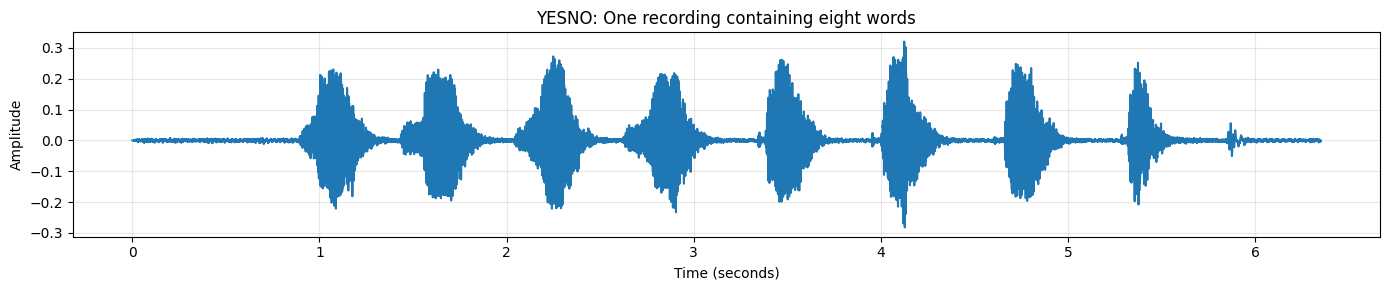

In [1]:
%pip -q install soundfile

from pathlib import Path
import torchaudio
import soundfile as sf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Audio, display

# Download the YESNO dataset
root = Path("/content/yesno_data")
root.mkdir(parents=True, exist_ok=True)

dataset = torchaudio.datasets.YESNO(
    root=str(root),
    url="https://www.openslr.org/resources/1/waves_yesno.tar.gz",
    download=True
)

# Select one recording
files = sorted((root / "waves_yesno").glob("*.wav"))
audio_path = files[0]

# Read the audio and its labels
signal, sample_rate = sf.read(audio_path)
labels = [int(value) for value in audio_path.stem.split("_")]
words = ["Yes" if value == 1 else "No" for value in labels]

print("Number of recordings:", len(dataset))
print("File:", audio_path.name)
print("Sample rate:", sample_rate, "Hz")
print("Duration:", round(len(signal) / sample_rate, 2), "seconds")
print("Labels:", labels)
print("Words:", " | ".join(words))

# Listen to the recording
display(Audio(signal, rate=sample_rate))

# Plot the waveform
time = np.arange(len(signal)) / sample_rate

plt.figure(figsize=(14, 3))
plt.plot(time, signal)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("YESNO: One recording containing eight words")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

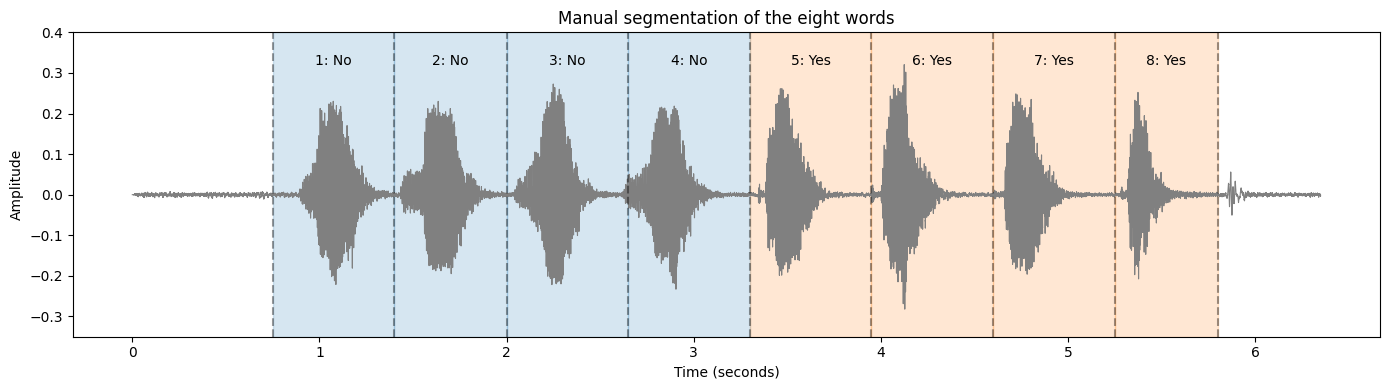

Word 1: No


Word 2: No


Word 3: No


Word 4: No


Word 5: Yes


Word 6: Yes


Word 7: Yes


Word 8: Yes


In [2]:
# These boundaries apply only to the recording shown previously
assert audio_path.stem == "0_0_0_0_1_1_1_1", (
    "The selected recording has changed."
)

# Approximate boundaries in seconds, placed between words
boundaries = [0.75, 1.40, 2.00, 2.65, 3.30,
              3.95, 4.60, 5.25, 5.80]

word_segments = []

# Show the proposed word regions
plt.figure(figsize=(14, 4))
plt.plot(time, signal, color="gray", linewidth=0.8)

for i, label in enumerate(labels):
    start = boundaries[i]
    end = boundaries[i + 1]

    segment = signal[
        round(start * sample_rate):round(end * sample_rate)
    ]
    word_segments.append(segment)

    color = "tab:blue" if label == 0 else "tab:orange"
    plt.axvspan(start, end, color=color, alpha=0.18)
    plt.axvline(start, color="black", linestyle="--", alpha=0.4)

    name = "Yes" if label == 1 else "No"
    plt.text((start + end) / 2, 0.32,
             f"{i + 1}: {name}", ha="center")

plt.axvline(boundaries[-1], color="black", linestyle="--", alpha=0.4)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Manual segmentation of the eight words")
plt.ylim(-0.35, 0.40)
plt.tight_layout()
plt.show()

# Listen to each word separately
for i, segment in enumerate(word_segments):
    name = "Yes" if labels[i] == 1 else "No"
    print(f"Word {i + 1}: {name}")
    display(Audio(segment, rate=sample_rate))

### Final preprocessing and evaluation
One recording with unresolved word labels is excluded. One other recording uses manually reviewed boundaries.

In [2]:
from pathlib import Path
import torchaudio
import soundfile as sf
import librosa

# Restore the dataset and file list
root = Path("/content/yesno_data")
root.mkdir(parents=True, exist_ok=True)

dataset = torchaudio.datasets.YESNO(
    root=str(root),
    url="https://www.openslr.org/resources/1/waves_yesno.tar.gz",
    download=True
)

files = sorted((root / "waves_yesno").glob("*.wav"))

# Restore our final segmentation settings
TOP_DB = 18
MERGE_GAP = 0.03
MIN_DURATION = 0.15
PADDING = 0.04

segmentation_results = {}

for path in files:
    audio, sr = sf.read(path)

    if audio.ndim > 1:
        audio = audio.mean(axis=1)

    intervals = librosa.effects.split(
        audio, top_db=TOP_DB,
        frame_length=256, hop_length=64
    )

    merged = []
    for start, end in intervals:
        start, end = int(start), int(end)

        if merged and (start - merged[-1][1]) / sr <= MERGE_GAP:
            merged[-1][1] = end
        else:
            merged.append([start, end])

    segmentation_results[path.name] = [
        [
            max(0, start - round(PADDING * sr)),
            min(len(audio), end + round(PADDING * sr))
        ]
        for start, end in merged
        if (end - start) / sr >= MIN_DURATION
    ]

# Restore the manual correction
manual_name = "1_1_0_1_1_1_1_0.wav"
_, manual_sr = sf.read(root / "waves_yesno" / manual_name)

manual_edges = [
    0.65, 1.40, 1.95, 2.45, 3.00,
    3.60, 4.20, 4.75, 5.20
]

segmentation_results[manual_name] = [
    [round(start * manual_sr), round(end * manual_sr)]
    for start, end in zip(manual_edges[:-1], manual_edges[1:])
]

# Exclude the unresolved recording
excluded_files = {
    "0_1_0_1_0_0_0_0.wav":
        "Seven words heard; filename contains eight labels."
}

usable_files = [
    path for path in files if path.name not in excluded_files
]

# Prepare individual words with their labels
word_samples = []

for path in usable_files:
    audio, sr = sf.read(path)

    if audio.ndim > 1:
        audio = audio.mean(axis=1)

    regions = segmentation_results[path.name]
    file_labels = [int(value) for value in path.stem.split("_")]

    assert len(regions) == len(file_labels) == 8, (
        f"Needs review: {path.name}"
    )

    for i, ((start, end), label) in enumerate(
        zip(regions, file_labels)
    ):
        word_samples.append({
            "audio": audio[start:end].copy(),
            "sample_rate": sr,
            "label": label,
            "recording": path.name,
            "word_number": i + 1
        })

print("Usable recordings:", len(usable_files))
print("Total word samples:", len(word_samples))
print("No samples:", sum(s["label"] == 0 for s in word_samples))
print("Yes samples:", sum(s["label"] == 1 for s in word_samples))

100%|██████████| 4.49M/4.49M [00:01<00:00, 2.83MB/s]


Usable recordings: 59
Total word samples: 472
No samples: 223
Yes samples: 249


In [3]:
import numpy as np
import pandas as pd
import torch
import torchaudio

assert all(s["sample_rate"] == 8000 for s in word_samples)

# Calculate 13 MFCC coefficients
mfcc_transform = torchaudio.transforms.MFCC(
    sample_rate=8000,
    n_mfcc=13,
    log_mels=True,
    melkwargs={
        "n_fft": 256,
        "win_length": 200,   # 25 milliseconds
        "hop_length": 80,    # 10 milliseconds
        "n_mels": 26,
        "center": False
    }
)

feature_rows = []

with torch.no_grad():
    for sample in word_samples:
        waveform = torch.tensor(
            sample["audio"], dtype=torch.float32
        )

        mfcc = mfcc_transform(waveform).numpy()

        # 13 means + 13 standard deviations
        features = np.concatenate([
            mfcc.mean(axis=1),
            mfcc.std(axis=1)
        ])

        feature_rows.append(features)

# Features, correct answers, and original recording IDs
X = np.stack(feature_rows)
y = np.array([s["label"] for s in word_samples])
groups = np.array([s["recording"] for s in word_samples])

assert np.isfinite(X).all(), "Invalid feature values detected."

feature_names = (
    [f"MFCC_{i}_mean" for i in range(1, 14)] +
    [f"MFCC_{i}_std" for i in range(1, 14)]
)

print("Feature matrix X:", X.shape)
print("Labels y:", y.shape)
print("Original recordings:", len(np.unique(groups)))
print("All feature values are finite:", np.isfinite(X).all())

# Preview a few features for the first five words
preview = pd.DataFrame(X[:5, :5], columns=feature_names[:5])
preview["Label"] = y[:5]
display(preview)

Feature matrix X: (472, 26)
Labels y: (472,)
Original recordings: 59
All feature values are finite: True


,MFCC_1_mean,MFCC_2_mean,MFCC_3_mean,MFCC_4_mean,MFCC_5_mean,Label
0,-19.486008,15.630932,-0.420590,0.360289,-3.856601,0
1,-22.159557,16.250774,0.553466,-1.669757,-2.569178,0
2,-21.372026,16.941822,1.099611,-1.660844,-3.520396,0
3,-23.021700,16.527365,1.528443,-2.350391,-2.426683,0
4,-16.359959,11.938832,0.693739,0.985124,-4.449050,1


In [4]:
from sklearn.model_selection import GroupShuffleSplit

# Split original recordings: approximately 80% train, 20% test
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

groups_train = groups[train_idx]
groups_test = groups[test_idx]

# Verify that no original recording appears in both sets
shared_recordings = set(groups_train) & set(groups_test)
assert len(shared_recordings) == 0

split_summary = pd.DataFrame([
    {
        "Set": "Train",
        "Recordings": len(np.unique(groups_train)),
        "Words": len(y_train),
        "No": int((y_train == 0).sum()),
        "Yes": int((y_train == 1).sum())
    },
    {
        "Set": "Test",
        "Recordings": len(np.unique(groups_test)),
        "Words": len(y_test),
        "No": int((y_test == 0).sum()),
        "Yes": int((y_test == 1).sum())
    }
])

display(split_summary)
print("Shared recordings:", len(shared_recordings))

,Set,Recordings,Words,No,Yes
0,Train,47,376,180,196
1,Test,12,96,43,53


Shared recordings: 0


In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Three classifiers with fixed settings
models = {
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=1.0, gamma="scale")
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

predictions = {}
result_rows = []

for name, model in models.items():
    # Learn from training words
    model.fit(X_train, y_train)

    # Predict unseen test words
    predicted = model.predict(X_test)
    predictions[name] = predicted

    correct = int((predicted == y_test).sum())

    result_rows.append({
        "Classifier": name,
        "Accuracy (%)": 100 * accuracy_score(y_test, predicted),
        "Macro F1 (%)": 100 * f1_score(
            y_test, predicted,
            average="macro",
            zero_division=0
        ),
        "Correct": correct,
        "Errors": len(y_test) - correct,
        "Test words": len(y_test)
    })

results = pd.DataFrame(result_rows)
display(results.round(2))

,Classifier,Accuracy (%),Macro F1 (%),Correct,Errors,Test words
0,KNN,100.0,100.0,96,0,96
1,SVM,100.0,100.0,96,0,96
2,Random Forest,100.0,100.0,96,0,96


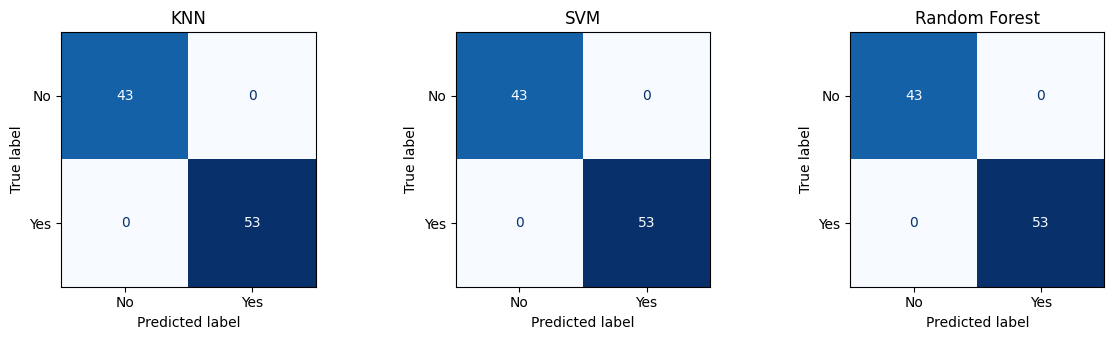

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

for ax, (name, predicted) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicted,
        labels=[0, 1],
        display_labels=["No", "Yes"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

## 2. Voice activity detection on VOiCES
Download the subset and apply pretrained Silero VAD to one example per background.

In [8]:
from pathlib import Path
import requests
from tqdm.auto import tqdm

subset_dir = Path("/content/voices_subset")
subset_dir.mkdir(parents=True, exist_ok=True)

base_url = (
    "https://raw.githubusercontent.com/"
    "Lab41/VOiCES-subset/master/"
)

for number in range(1, 9):
    name = f"VOiCES_90_{number}.tar"
    destination = subset_dir / name
    temporary = subset_dir / f"{name}.part"

    with requests.get(
        base_url + name,
        stream=True,
        timeout=(30, 120)
    ) as response:
        response.raise_for_status()
        expected = int(response.headers.get("Content-Length", 0))

        if (expected and destination.exists()
                and destination.stat().st_size == expected):
            print(name, "already downloaded.")
            continue

        with open(temporary, "wb") as output:
            with tqdm(
                total=expected or None,
                unit="B",
                unit_scale=True,
                desc=name
            ) as progress:
                for chunk in response.iter_content(1024 * 1024):
                    if chunk:
                        output.write(chunk)
                        progress.update(len(chunk))

    if expected and temporary.stat().st_size != expected:
        raise RuntimeError(f"Incomplete download: {name}")

    temporary.replace(destination)

archive_files = sorted(subset_dir.glob("VOiCES_90_*.tar"))

print("\nDownloaded archives:", len(archive_files))
print(
    "Total size:",
    round(sum(p.stat().st_size for p in archive_files) / 1024**2, 2),
    "MiB"
)

VOiCES_90_1.tar:   0%|          | 0.00/47.6M [00:00<?, ?B/s]

VOiCES_90_2.tar:   0%|          | 0.00/48.1M [00:00<?, ?B/s]

VOiCES_90_3.tar:   0%|          | 0.00/48.2M [00:00<?, ?B/s]

VOiCES_90_4.tar:   0%|          | 0.00/47.2M [00:00<?, ?B/s]

VOiCES_90_5.tar:   0%|          | 0.00/47.1M [00:00<?, ?B/s]

VOiCES_90_6.tar:   0%|          | 0.00/46.1M [00:00<?, ?B/s]

VOiCES_90_7.tar:   0%|          | 0.00/46.9M [00:00<?, ?B/s]

VOiCES_90_8.tar:   0%|          | 0.00/48.4M [00:00<?, ?B/s]


Downloaded archives: 8
Total size: 362.05 MiB


In [9]:
import tarfile
import shutil
import re
import soundfile as sf
import pandas as pd
from pathlib import Path

subset_dir = Path("/content/voices_subset")
audio_dir = subset_dir / "audio"
audio_dir.mkdir(parents=True, exist_ok=True)

archive_files = sorted(subset_dir.glob("VOiCES_90_*.tar"))
assert len(archive_files) == 8, "Some archives are missing."

# Extract regular WAV files
for archive in archive_files:
    with tarfile.open(archive, "r:*") as tar:
        for member in tar:
            member_path = Path(member.name)

            if (
                not member.isfile()
                or member_path.suffix.lower() != ".wav"
                or member_path.name.startswith("._")
                or "__MACOSX" in member_path.parts
            ):
                continue

            target = (audio_dir / member.name).resolve()

            if not target.is_relative_to(audio_dir.resolve()):
                raise RuntimeError("Unexpected archive path.")

            target.parent.mkdir(parents=True, exist_ok=True)

            if target.exists() and target.stat().st_size == member.size:
                continue

            with tar.extractfile(member) as source:
                with open(target, "wb") as output:
                    shutil.copyfileobj(source, output)

# Inspect audio files and background labels
voices_wavs = sorted(
    p for p in audio_dir.rglob("*")
    if p.is_file() and p.suffix.lower() == ".wav"
)

rows = []

for path in voices_wavs:
    info = sf.info(path)

    match = re.search(
        r"-(none|babb|musi|tele)-",
        path.name,
        flags=re.IGNORECASE
    )

    rows.append({
        "File": path.name,
        "Path": str(path),
        "Background": match.group(1).lower() if match else "unknown",
        "Sample_rate": info.samplerate,
        "Duration_s": round(info.duration, 2)
    })

voices_metadata = pd.DataFrame(rows)
assert not voices_metadata.empty, "No WAV files were found."

print("Total WAV files:", len(voices_metadata))
print("Sample rates:", sorted(
    voices_metadata["Sample_rate"].unique().tolist()
))

print("\nRecordings per background:")
display(
    voices_metadata.groupby("Background")
    .size()
    .reset_index(name="Recordings")
)

print("\nExample files:")
display(
    voices_metadata[["File", "Background", "Duration_s"]].head(8)
)

Total WAV files: 908
Sample rates: [16000]

Recordings per background:


,Background,Recordings
0,babb,228
1,musi,231
2,none,227
3,tele,222



Example files:


,File,Background,Duration_s
0,Lab41-SRI-VOiCES-rm1-babb-sp0093-ch126208-sg00...,babb,15.84
1,Lab41-SRI-VOiCES-rm1-babb-sp0188-ch135249-sg00...,babb,16.35
2,Lab41-SRI-VOiCES-rm1-babb-sp0242-ch122625-sg00...,babb,15.20
3,Lab41-SRI-VOiCES-rm1-babb-sp0636-ch128331-sg00...,babb,16.75
4,Lab41-SRI-VOiCES-rm1-babb-sp1066-ch005330-sg00...,babb,16.37
5,Lab41-SRI-VOiCES-rm1-babb-sp2532-ch157475-sg00...,babb,15.67
6,Lab41-SRI-VOiCES-rm1-babb-sp4064-ch077779-sg00...,babb,15.54
7,Lab41-SRI-VOiCES-rm1-babb-sp4160-ch011550-sg00...,babb,14.75


Speech without added distractor
File: Lab41-SRI-VOiCES-rm1-none-sp0083-ch003054-sg0005-mc05-stu-far-dg090.wav
Duration: 16.07 seconds


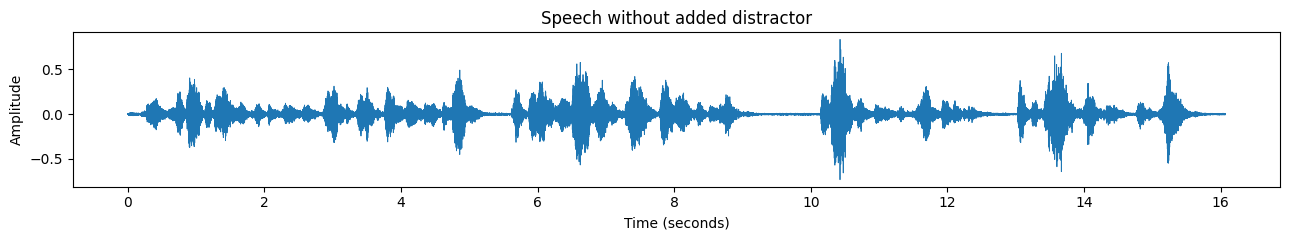

Speech with music
File: Lab41-SRI-VOiCES-rm1-musi-sp0150-ch126107-sg0026-mc07-stu-beh-dg090.wav
Duration: 16.16 seconds


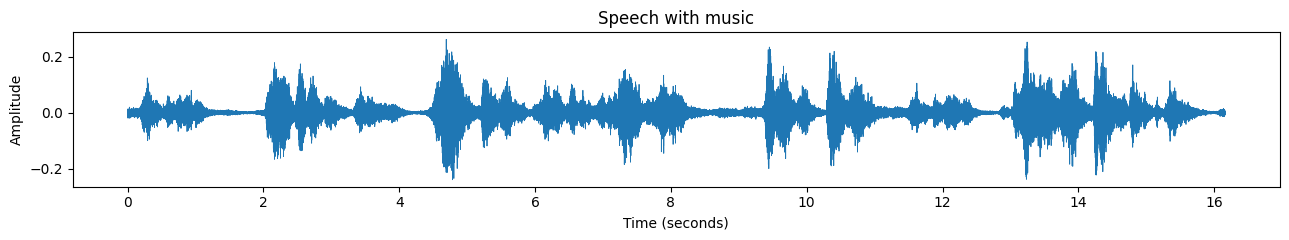

Speech with television
File: Lab41-SRI-VOiCES-rm1-tele-sp0093-ch126208-sg0004-mc07-stu-beh-dg090.wav
Duration: 15.84 seconds


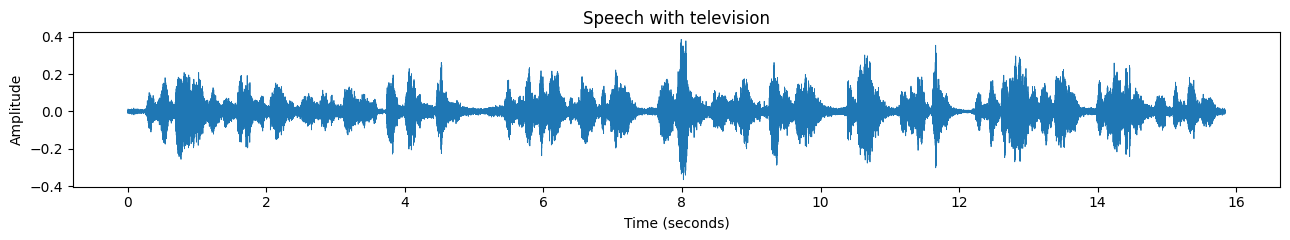

Speech with babble
File: Lab41-SRI-VOiCES-rm1-babb-sp0093-ch126208-sg0004-mc05-stu-far-dg090.wav
Duration: 15.84 seconds


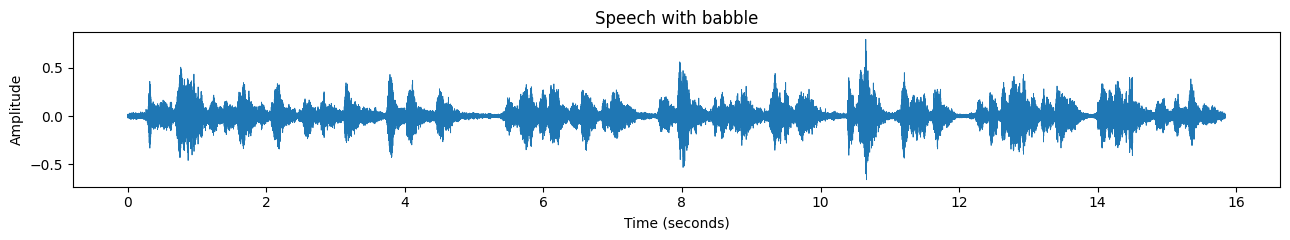

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from IPython.display import Audio, display

voices_examples = {}

background_names = {
    "none": "Speech without added distractor",
    "musi": "Speech with music",
    "tele": "Speech with television",
    "babb": "Speech with babble"
}

for background, description in background_names.items():
    row = voices_metadata[
        voices_metadata["Background"] == background
    ].iloc[0]

    clip_audio, clip_sr = sf.read(row["Path"])

    if clip_audio.ndim > 1:
        clip_audio = clip_audio.mean(axis=1)

    voices_examples[background] = {
        "audio": clip_audio,
        "sample_rate": clip_sr,
        "path": row["Path"]
    }

    print(description)
    print("File:", row["File"])
    print(f"Duration: {len(clip_audio) / clip_sr:.2f} seconds")

    display(Audio(clip_audio, rate=clip_sr))

    clip_time = np.arange(len(clip_audio)) / clip_sr
    plt.figure(figsize=(13, 2.5))
    plt.plot(clip_time, clip_audio, linewidth=0.6)
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.title(description)
    plt.tight_layout()
    plt.show()

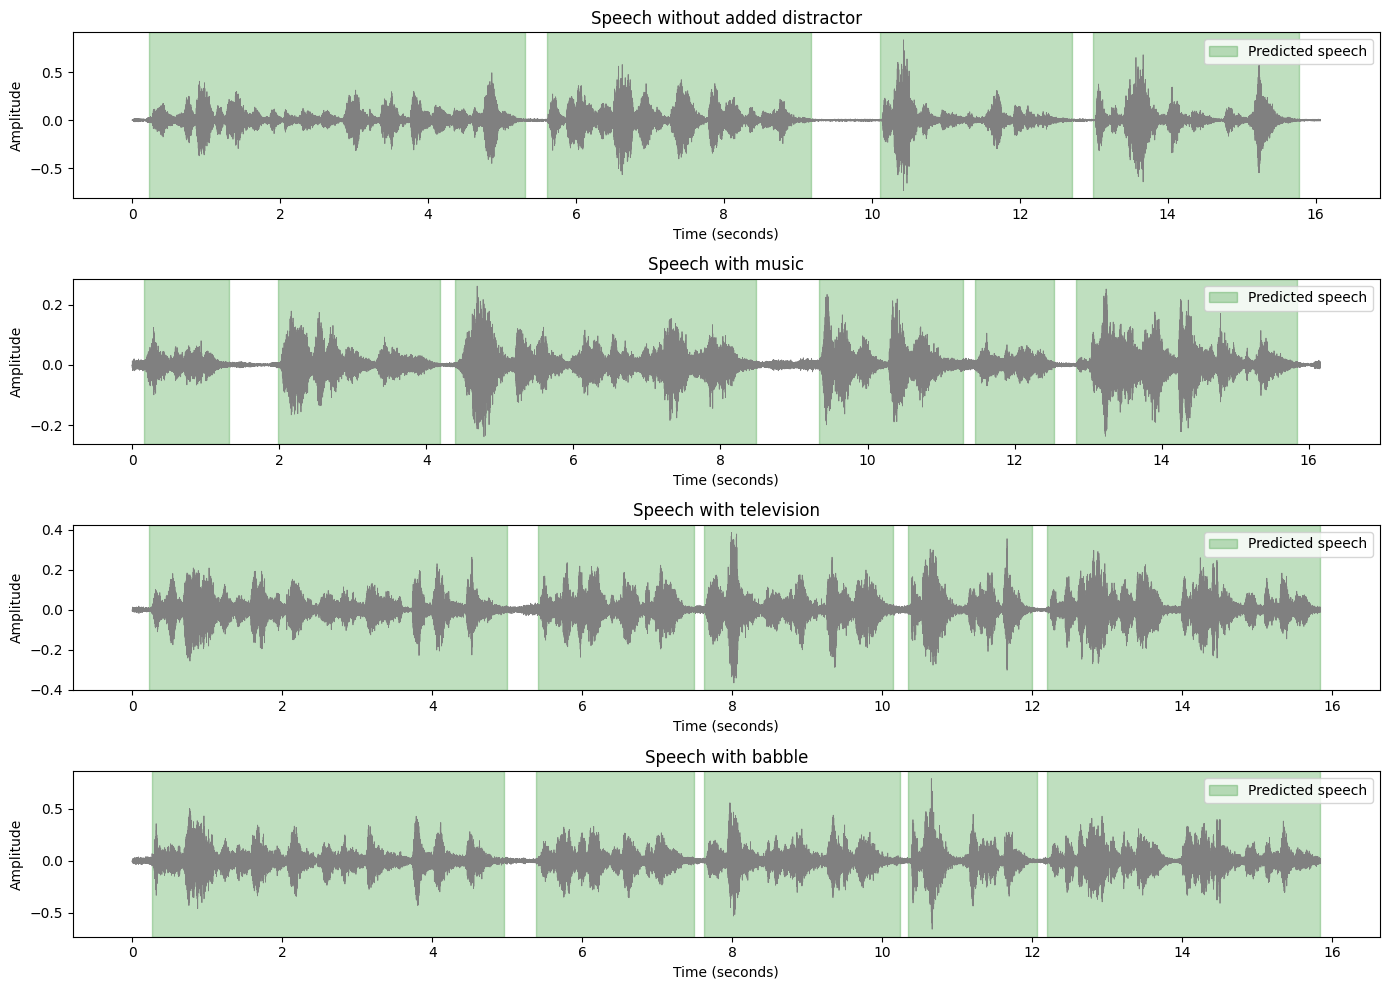

,Background,Duration_s,Speech_regions,Detected_speech_s,Detected_speech_%
0,none,16.07,4,14.03,87.35
1,musi,16.16,6,13.48,83.42
2,tele,15.84,5,14.67,92.61
3,babb,15.84,5,14.80,93.42


In [11]:
%pip -q install silero-vad

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from silero_vad import load_silero_vad, get_speech_timestamps

torch.set_num_threads(1)
vad_model = load_silero_vad()

vad_results = {}
vad_summary_rows = []

fig, axes = plt.subplots(4, 1, figsize=(14, 10))

for ax, (background, description) in zip(
    axes, background_names.items()
):
    example = voices_examples[background]
    audio = example["audio"]
    sr = example["sample_rate"]

    assert sr == 16000

    waveform = torch.tensor(audio, dtype=torch.float32)

    # Detect speech regions; timestamps are in samples
    timestamps = get_speech_timestamps(
        waveform,
        vad_model,
        sampling_rate=sr,
        threshold=0.5,
        min_speech_duration_ms=250,
        min_silence_duration_ms=100,
        speech_pad_ms=30,
        return_seconds=False
    )

    vad_results[background] = {
        "path": example["path"],
        "sample_rate": sr,
        "timestamps": timestamps
    }

    duration = len(audio) / sr
    speech_duration = sum(
        (region["end"] - region["start"]) / sr
        for region in timestamps
    )

    vad_summary_rows.append({
        "Background": background,
        "Duration_s": duration,
        "Speech_regions": len(timestamps),
        "Detected_speech_s": speech_duration,
        "Detected_speech_%": 100 * speech_duration / duration
    })

    t = np.arange(len(audio)) / sr
    ax.plot(t, audio, color="gray", linewidth=0.6)

    for i, region in enumerate(timestamps):
        ax.axvspan(
            region["start"] / sr,
            region["end"] / sr,
            color="green",
            alpha=0.25,
            label="Predicted speech" if i == 0 else None
        )

    ax.set_title(description)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")

    if timestamps:
        ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

vad_summary = pd.DataFrame(vad_summary_rows)
display(vad_summary.round(2))

## 3. Sound event detection on VOiCES
YAMNet detects speech and music with an exploratory score threshold of 0.30. The four recordings illustrate the workflow. Temporal accuracy requires reference annotations.

In [12]:
# Install Hub with a Keras package matching Colab's TensorFlow
import sys
import subprocess
import importlib.metadata as metadata

tf_minor = ".".join(
    metadata.version("tensorflow").split(".")[:2]
)

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "--no-deps",
    "tensorflow-hub==0.16.1",
    f"tf-keras~={tf_minor}.0"
])

import tensorflow as tf
import tensorflow_hub as hub
import numpy as np
import pandas as pd
import csv

# Load the pretrained sound-event model
yamnet_model = hub.load("https://tfhub.dev/google/yamnet/1")

class_map_path = yamnet_model.class_map_path().numpy().decode("utf-8")

with tf.io.gfile.GFile(class_map_path) as csv_file:
    yamnet_classes = [
        row["display_name"]
        for row in csv.DictReader(csv_file)
    ]

# Analyze the VOiCES recording with a music background
example = voices_examples["musi"]
assert example["sample_rate"] == 16000

yamnet_audio = np.asarray(example["audio"], dtype=np.float32)

scores, embeddings, spectrogram = yamnet_model(yamnet_audio)
music_example_scores = scores.numpy()

# Show the five highest average scores
average_scores = music_example_scores.mean(axis=0)
top_indices = np.argsort(average_scores)[::-1][:5]

top_events = pd.DataFrame({
    "Detected sound": [yamnet_classes[i] for i in top_indices],
    "Mean score": [float(average_scores[i]) for i in top_indices]
})

print("Model loaded. Number of classes:", len(yamnet_classes))
display(top_events.round(4))

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Model loaded. Number of classes: 521


,Detected sound,Mean score
0,Speech,0.6468
1,Music,0.0810
2,"Inside, small room",0.0108
3,"Narration, monologue",0.0078
4,Musical instrument,0.0045


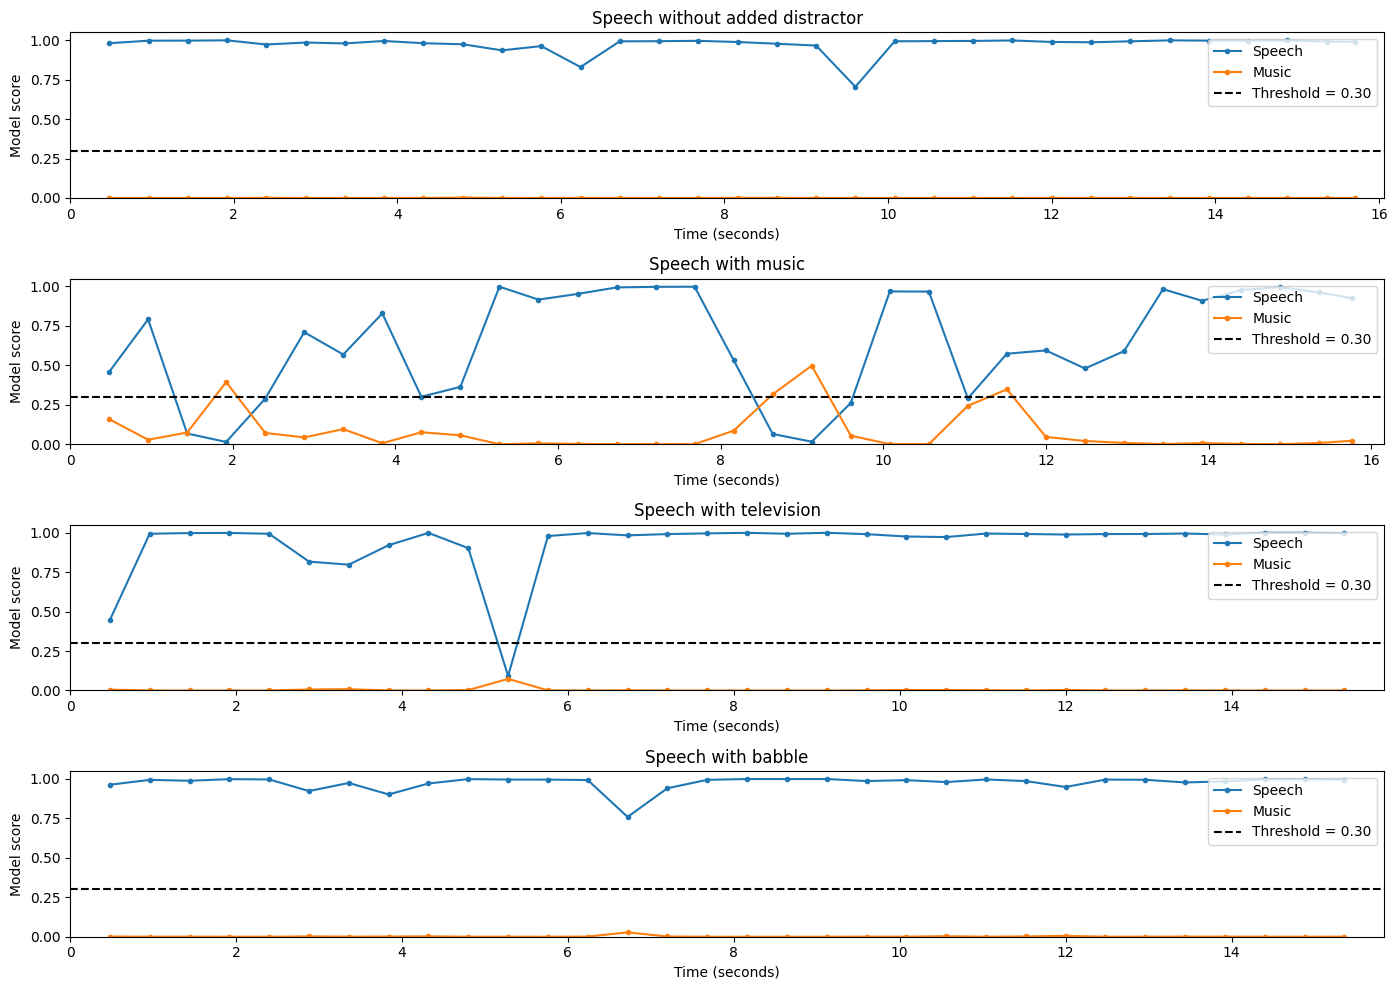

Detection summary:


,Background,Event,Peak_score,Detected_intervals
0,none,Speech,0.999,1
1,none,Music,0.002,0
2,musi,Speech,0.999,3
3,musi,Music,0.498,3
4,tele,Speech,1.000,1
5,tele,Music,0.074,0
6,babb,Speech,1.000,1
7,babb,Music,0.027,0


Approximate detected event intervals:


,Background,Event,Start_s,End_s,Peak_score
0,none,Speech,0.00,16.065,0.999
1,musi,Speech,0.00,1.440,0.791
2,musi,Speech,2.40,8.640,0.999
3,musi,Speech,9.60,16.160,0.996
4,musi,Music,1.44,2.400,0.394
5,musi,Music,8.16,9.600,0.498
6,musi,Music,11.04,12.000,0.348
7,tele,Speech,0.00,15.840,1.000
8,babb,Speech,0.00,15.840,1.000


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EVENT_THRESHOLD = 0.30
PATCH_WINDOW = 0.96
PATCH_HOP = 0.48

event_names = ["Speech", "Music"]
event_indices = {
    name: yamnet_classes.index(name) for name in event_names
}

event_results = {}
event_rows = []
event_summary_rows = []

fig, axes = plt.subplots(4, 1, figsize=(14, 10))

for ax, (background, description) in zip(
    axes, background_names.items()
):
    example = voices_examples[background]
    audio = np.asarray(example["audio"], dtype=np.float32)
    sr = example["sample_rate"]
    assert sr == 16000

    scores, _, _ = yamnet_model(audio)
    frame_scores = scores.numpy()

    duration = len(audio) / sr
    starts = np.arange(len(frame_scores)) * PATCH_HOP

    # Discard any window starting beyond the original recording
    valid = starts < duration
    starts = starts[valid]
    frame_scores = frame_scores[valid]
    ends = np.minimum(starts + PATCH_WINDOW, duration)
    centers = (starts + ends) / 2

    event_results[background] = {
        "path": example["path"],
        "scores": frame_scores,
        "window_starts": starts,
        "window_ends": ends
    }

    for event in event_names:
        values = frame_scores[:, event_indices[event]]
        ax.plot(centers, values, marker=".", label=event)

        # Merge overlapping windows above the threshold
        intervals = []

        for i in np.flatnonzero(values >= EVENT_THRESHOLD):
            start, end = float(starts[i]), float(ends[i])
            score = float(values[i])

            if intervals and start <= intervals[-1]["End_s"] + 1e-8:
                intervals[-1]["End_s"] = max(
                    intervals[-1]["End_s"], end
                )
                intervals[-1]["Peak_score"] = max(
                    intervals[-1]["Peak_score"], score
                )
            else:
                intervals.append({
                    "Start_s": start,
                    "End_s": end,
                    "Peak_score": score
                })

        event_summary_rows.append({
            "Background": background,
            "Event": event,
            "Peak_score": float(values.max()),
            "Detected_intervals": len(intervals)
        })

        for interval in intervals:
            event_rows.append({
                "Background": background,
                "Event": event,
                **interval
            })

    ax.axhline(
        EVENT_THRESHOLD, color="black", linestyle="--",
        label="Threshold = 0.30"
    )
    ax.set_title(description)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Model score")
    ax.set_ylim(0, 1.05)
    ax.set_xlim(0, duration)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

event_summary = pd.DataFrame(event_summary_rows)
event_intervals = pd.DataFrame(
    event_rows,
    columns=["Background", "Event", "Start_s", "End_s", "Peak_score"]
)

print("Detection summary:")
display(event_summary.round(3))

print("Approximate detected event intervals:")
display(event_intervals.round(3))

## Export results

In [14]:
from pathlib import Path
import shutil
from google.colab import files as colab_files

output_dir = Path("/content/Audio_Assignment_Results")
output_dir.mkdir(parents=True, exist_ok=True)

tables = {
    "YESNO_Classifier_Results.csv": results,
    "YESNO_Train_Test_Split.csv": split_summary,
    "VOICES_VAD_Summary.csv": vad_summary,
    "VOICES_Event_Summary.csv": event_summary,
    "VOICES_Event_Intervals.csv": event_intervals,
    "VOICES_Data_Inventory.csv": voices_metadata
}

for filename, table in tables.items():
    table.to_csv(output_dir / filename, index=False,
                 encoding="utf-8-sig")

zip_path = shutil.make_archive(
    "/content/Audio_Assignment_Results",
    "zip",
    root_dir=output_dir
)

colab_files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>